# Retail Price Prediction: Data Understanding and Validation

This notebook loads `retail_price.csv`, validates its structure and quality, corrects column names in memory, converts the date field, examines the proposed target variable, checks price consistency, and creates initial exploratory visualizations.

**Proposed target:** `unit_price`


## 1. Import libraries


In [6]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


## 2. Locate and load the dataset

The code supports the recommended project structure (`data/retail_price.csv`) and also works if the notebook and CSV are in the same folder.


In [7]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path(
    r"C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone\data\raw\retail_price.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"retail_price.csv was not found at:\n{DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

print(f"Loaded: {DATA_PATH.resolve()}")
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")

df.head()

Loaded: C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone\data\raw\retail_price.csv
Dataset shape: 676 rows x 30 columns


,product_id,product_category_name,month_year,qty,total_price,freight_price,unit_price,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_score,customers,weekday,weekend,holiday,month,year,s,volume,comp_1,ps1,fp1,comp_2,ps2,fp2,comp_3,ps3,fp3,lag_price
0,bed1,bed_bath_table,01-05-2017,1,45.95,15.10,45.95,39,161,2,350,4.00,57,23,8,1,5,2017,10.27,3800,89.90,3.90,15.01,215.00,4.40,8.76,45.95,4.00,15.10,45.90
1,bed1,bed_bath_table,01-06-2017,3,137.85,12.93,45.95,39,161,2,350,4.00,61,22,8,1,6,2017,6.50,3800,89.90,3.90,14.77,209.00,4.40,21.32,45.95,4.00,12.93,45.95
2,bed1,bed_bath_table,01-07-2017,6,275.70,14.84,45.95,39,161,2,350,4.00,123,21,10,1,7,2017,12.07,3800,89.90,3.90,13.99,205.00,4.40,22.20,45.95,4.00,14.84,45.95
3,bed1,bed_bath_table,01-08-2017,4,183.80,14.29,45.95,39,161,2,350,4.00,90,23,8,1,8,2017,9.29,3800,89.90,3.90,14.66,199.51,4.40,19.41,45.95,4.00,14.29,45.95
4,bed1,bed_bath_table,01-09-2017,2,91.90,15.10,45.95,39,161,2,350,4.00,54,21,9,1,9,2017,5.56,3800,89.90,3.90,18.78,163.40,4.40,24.32,45.95,4.00,15.10,45.95


## 3. Inspect the dataset structure


In [8]:
print("Column names:")
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values}))

print("Dataset information:")
df.info()


Column names:


,column,dtype
0,product_id,str
1,product_category_name,str
2,month_year,str
3,qty,int64
4,total_price,float64
5,freight_price,float64
6,unit_price,float64
7,product_name_lenght,int64
8,product_description_lenght,int64
9,product_photos_qty,int64


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 676 entries, 0 to 675
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  676 non-null    str    
 1   product_category_name       676 non-null    str    
 2   month_year                  676 non-null    str    
 3   qty                         676 non-null    int64  
 4   total_price                 676 non-null    float64
 5   freight_price               676 non-null    float64
 6   unit_price                  676 non-null    float64
 7   product_name_lenght         676 non-null    int64  
 8   product_description_lenght  676 non-null    int64  
 9   product_photos_qty          676 non-null    int64  
 10  product_weight_g            676 non-null    int64  
 11  product_score               676 non-null    float64
 12  customers                   676 non-null    int64  
 13  weekday                  

## 4. Correct column-name spelling

The source CSV remains unchanged. The corrections are applied only to the DataFrame.


In [9]:
df = df.rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length",
})

df.columns.tolist()


['product_id',
 'product_category_name',
 'month_year',
 'qty',
 'total_price',
 'freight_price',
 'unit_price',
 'product_name_length',
 'product_description_length',
 'product_photos_qty',
 'product_weight_g',
 'product_score',
 'customers',
 'weekday',
 'weekend',
 'holiday',
 'month',
 'year',
 's',
 'volume',
 'comp_1',
 'ps1',
 'fp1',
 'comp_2',
 'ps2',
 'fp2',
 'comp_3',
 'ps3',
 'fp3',
 'lag_price']

## 5. Convert and validate the date column


In [10]:
df["month_year"] = pd.to_datetime(
    df["month_year"],
    format="%d-%m-%Y",
    errors="raise",
)

df = df.sort_values(["product_id", "month_year"]).reset_index(drop=True)

print("Minimum date:", df["month_year"].min().date())
print("Maximum date:", df["month_year"].max().date())
print("Number of distinct months:", df["month_year"].nunique())


Minimum date: 2017-01-01
Maximum date: 2018-08-01
Number of distinct months: 20


## 6. Data-quality summary


In [11]:
quality_summary = pd.Series({
    "Rows": len(df),
    "Columns": df.shape[1],
    "Exact duplicate rows": df.duplicated().sum(),
    "Total missing values": df.isna().sum().sum(),
    "Unique products": df["product_id"].nunique(),
    "Unique categories": df["product_category_name"].nunique(),
})
quality_summary.to_frame("value")


,value
Rows,676
Columns,30
Exact duplicate rows,0
Total missing values,0
Unique products,52
Unique categories,9


In [12]:
missing_by_column = df.isna().sum().sort_values(ascending=False)
missing_by_column = missing_by_column[missing_by_column > 0]

if missing_by_column.empty:
    print("No missing values were found.")
else:
    display(missing_by_column.to_frame("missing_count"))


No missing values were found.


## 7. Descriptive statistics


In [13]:
df.describe(include="all").T


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
product_id,676,52,health5,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category_name,676,9,garden_tools,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month_year,676,NaN,NaN,NaN,2017-12-15 17:47:13.136094,2017-01-01 00:00:00,2017-09-01 00:00:00,2018-01-01 00:00:00,2018-04-01 00:00:00,2018-08-01 00:00:00,NaN
qty,676.00,NaN,NaN,NaN,14.50,1.00,4.00,10.00,18.00,122.00,15.44
total_price,676.00,NaN,NaN,NaN,"1,422.71",19.90,333.70,807.89,"1,887.32","12,095.00","1,700.12"
freight_price,676.00,NaN,NaN,NaN,20.68,0.00,14.76,17.52,22.71,79.76,10.08
unit_price,676.00,NaN,NaN,NaN,106.50,19.90,53.90,89.90,129.99,364.00,76.18
product_name_length,676.00,NaN,NaN,NaN,48.72,29.00,40.00,51.00,57.00,60.00,9.42
product_description_length,676.00,NaN,NaN,NaN,767.40,100.00,339.00,501.00,903.00,"3,006.00",655.21
product_photos_qty,676.00,NaN,NaN,NaN,1.99,1.00,1.00,1.50,2.00,8.00,1.42


## 8. Product-category coverage


In [14]:
category_summary = (
    df.groupby("product_category_name")
      .agg(
          records=("product_id", "size"),
          products=("product_id", "nunique"),
          average_unit_price=("unit_price", "mean"),
          total_quantity=("qty", "sum"),
      )
      .sort_values("records", ascending=False)
)
category_summary


,records,products,average_unit_price,total_quantity
product_category_name,,,,
garden_tools,160,10,80.09,2398
health_beauty,130,10,132.31,1842
watches_gifts,103,8,164.88,1431
computers_accessories,69,6,119.48,1167
bed_bath_table,61,5,78.63,1026
cool_stuff,57,5,107.86,558
furniture_decor,48,4,60.15,894
perfumery,26,2,89.35,244
consoles_games,22,2,27.03,239


## 9. Examine the proposed target

For the first modelling iteration, `unit_price` is treated as the target variable.


In [15]:
TARGET = "unit_price"
df[TARGET].describe().to_frame("value")


,value
count,676.00
mean,106.50
std,76.18
min,19.90
25%,53.90
50%,89.90
75%,129.99
max,364.00


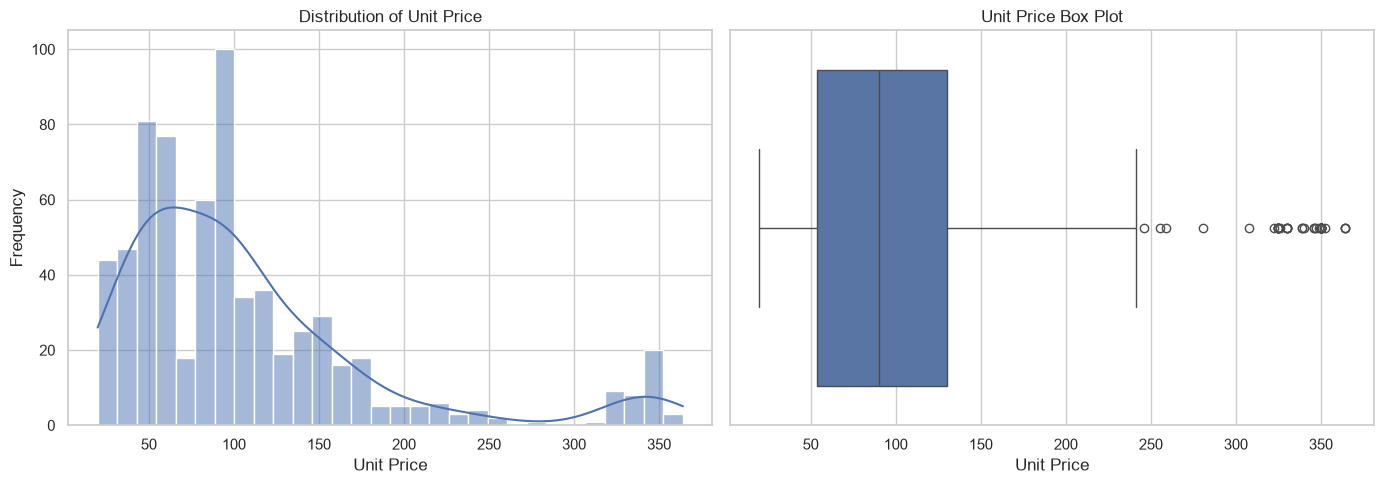

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df[TARGET], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Unit Price")
axes[0].set_xlabel("Unit Price")
axes[0].set_ylabel("Frequency")

sns.boxplot(x=df[TARGET], ax=axes[1])
axes[1].set_title("Unit Price Box Plot")
axes[1].set_xlabel("Unit Price")

plt.tight_layout()
plt.show()


## 10. Check total-price consistency

Rows with differences are flagged for investigation, not automatically removed. `total_price` may use a business definition different from a simple `qty × unit_price` calculation.


In [17]:
df["calculated_total_price"] = df["qty"] * df["unit_price"]
df["total_price_difference"] = (
    df["total_price"] - df["calculated_total_price"]
).abs()

TOLERANCE = 0.10
inconsistent_rows = df["total_price_difference"] > TOLERANCE

print(f"Rows with an absolute difference above {TOLERANCE}: {inconsistent_rows.sum():,}")
print(f"Percentage of rows flagged: {inconsistent_rows.mean():.2%}")

df.loc[inconsistent_rows, [
    "product_id", "month_year", "qty", "unit_price",
    "total_price", "calculated_total_price", "total_price_difference"
]].sort_values("total_price_difference", ascending=False).head(20)


Rows with an absolute difference above 0.1: 73
Percentage of rows flagged: 10.80%


,product_id,month_year,qty,unit_price,total_price,calculated_total_price,total_price_difference
116,computers5,2018-01-01,57,93.09,"5,453.96","5,306.41",147.55
643,watches6,2017-09-01,18,148.78,"2,762.50","2,678.01",84.49
361,garden6,2017-12-01,51,55.10,"2,881.60","2,810.10",71.50
86,computers3,2017-05-01,15,178.06,"2,715.70","2,670.86",44.84
281,garden10,2017-11-01,87,53.65,"4,712.19","4,667.40",44.79
633,watches5,2017-11-01,12,203.29,"2,395.20","2,439.49",44.29
665,watches7,2018-07-01,45,169.35,"7,651.27","7,620.72",30.55
407,garden9,2017-11-01,82,53.38,"4,397.70","4,377.09",20.61
649,watches6,2018-04-01,85,105.65,"8,961.49","8,980.13",18.64
263,garden1,2017-09-01,7,102.50,735.00,717.50,17.50


## 11. Check product-month uniqueness and history length


In [18]:
product_month_duplicates = df.duplicated(
    subset=["product_id", "month_year"]
).sum()

print("Duplicate product-month combinations:", product_month_duplicates)

product_history = (
    df.groupby("product_id")
      .agg(
          first_month=("month_year", "min"),
          last_month=("month_year", "max"),
          number_of_records=("month_year", "size"),
          distinct_months=("month_year", "nunique"),
      )
      .sort_values(["distinct_months", "product_id"])
)

product_history


Duplicate product-month combinations: 0


,first_month,last_month,number_of_records,distinct_months
product_id,,,,
bed5,2017-05-01,2017-09-01,5,5
cool3,2017-09-01,2018-08-01,7,7
health10,2018-02-01,2018-08-01,7,7
health6,2018-01-01,2018-08-01,7,7
computers5,2017-10-01,2018-07-01,8,8
computers6,2018-01-01,2018-08-01,8,8
health3,2018-01-01,2018-08-01,8,8
cool4,2017-07-01,2018-04-01,9,9
health1,2017-08-01,2018-06-01,9,9


## 12. Initial exploratory visualizations


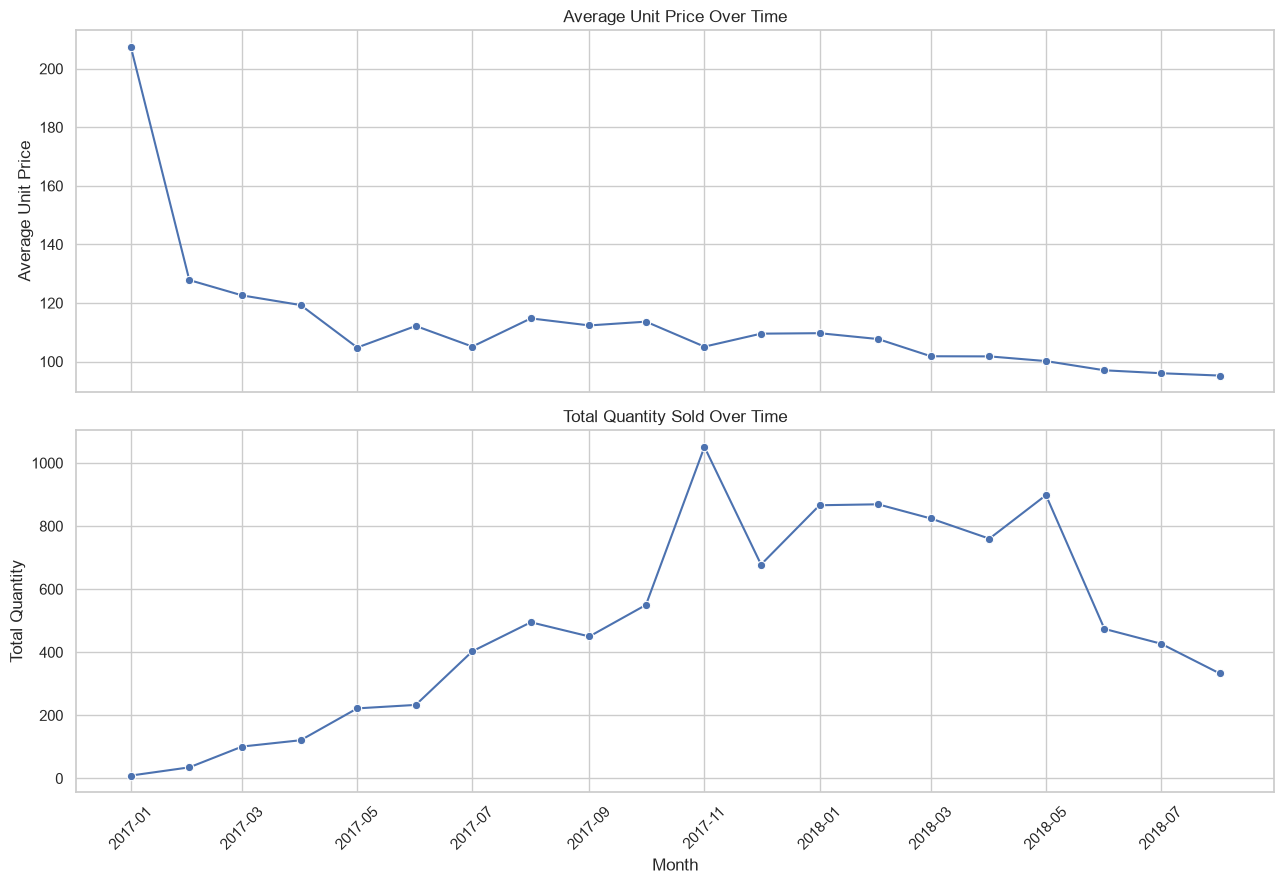

In [19]:
monthly_summary = (
    df.groupby("month_year", as_index=False)
      .agg(
          average_unit_price=("unit_price", "mean"),
          total_quantity=("qty", "sum"),
          average_freight_price=("freight_price", "mean"),
      )
)

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

sns.lineplot(
    data=monthly_summary, x="month_year", y="average_unit_price",
    marker="o", ax=axes[0]
)
axes[0].set_title("Average Unit Price Over Time")
axes[0].set_xlabel("")
axes[0].set_ylabel("Average Unit Price")

sns.lineplot(
    data=monthly_summary, x="month_year", y="total_quantity",
    marker="o", ax=axes[1]
)
axes[1].set_title("Total Quantity Sold Over Time")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Total Quantity")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


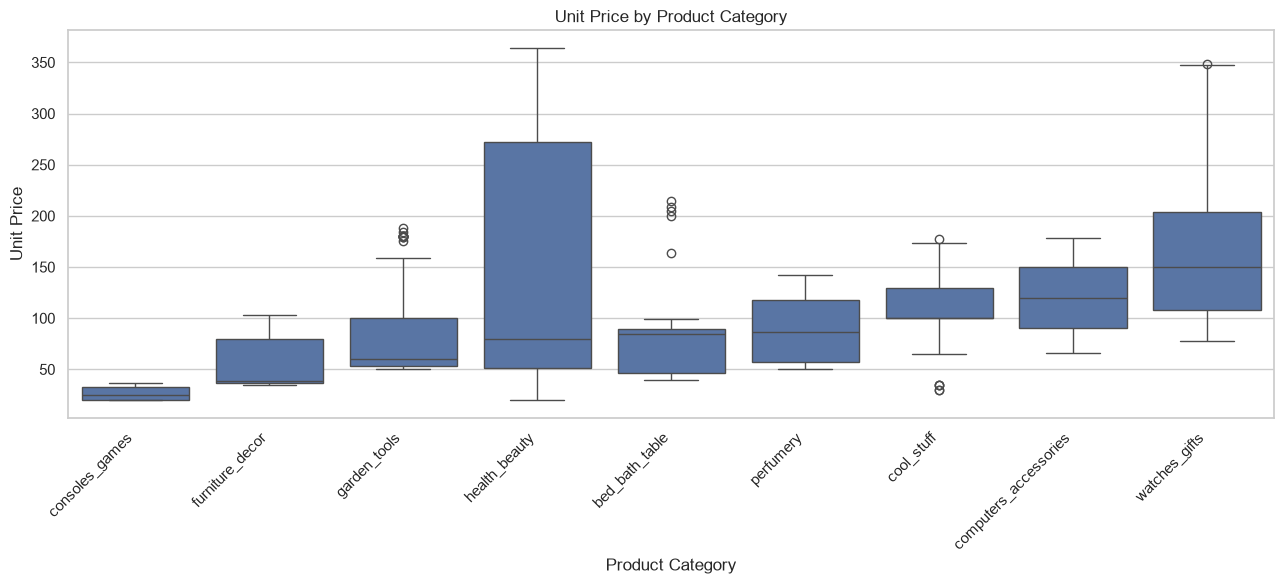

In [20]:
plt.figure(figsize=(13, 6))
category_order = (
    df.groupby("product_category_name")["unit_price"]
      .median()
      .sort_values()
      .index
)

sns.boxplot(
    data=df,
    x="product_category_name",
    y="unit_price",
    order=category_order,
)
plt.title("Unit Price by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Unit Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 13. Numerical correlation with unit price


In [21]:
numeric_columns = df.select_dtypes(include=np.number).columns
target_correlations = (
    df[numeric_columns]
      .corr()[TARGET]
      .drop(TARGET)
      .sort_values(key=np.abs, ascending=False)
)

target_correlations.to_frame("correlation_with_unit_price")


,correlation_with_unit_price
lag_price,0.99
comp_2,0.47
calculated_total_price,0.41
total_price,0.41
comp_3,0.38
comp_1,0.32
product_description_length,0.28
ps3,-0.24
freight_price,0.20
ps1,0.20


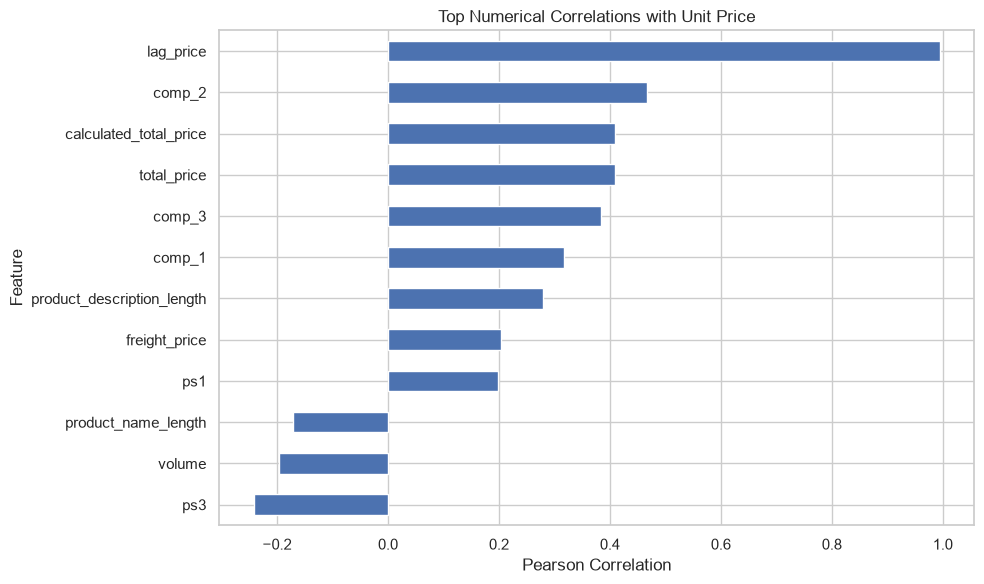

In [22]:
top_features = target_correlations.head(12).sort_values()

plt.figure(figsize=(10, 6))
top_features.plot(kind="barh")
plt.title("Top Numerical Correlations with Unit Price")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 14. Check lag-price validity

This compares the supplied `lag_price` with the previous recorded `unit_price` for each product. Differences should be investigated before modelling.


In [23]:
df["calculated_lag_price"] = df.groupby("product_id")["unit_price"].shift(1)
df["lag_price_difference"] = (
    df["lag_price"] - df["calculated_lag_price"]
).abs()

lag_comparison = df[df["calculated_lag_price"].notna()].copy()

print("Comparable rows:", len(lag_comparison))
print("Exact or near matches:", (lag_comparison["lag_price_difference"] <= 0.01).sum())
print("Rows differing by more than 0.01:", (lag_comparison["lag_price_difference"] > 0.01).sum())

lag_comparison[[
    "product_id", "month_year", "unit_price", "lag_price",
    "calculated_lag_price", "lag_price_difference"
]].sort_values("lag_price_difference", ascending=False).head(20)


Comparable rows: 624
Exact or near matches: 595
Rows differing by more than 0.01: 29


,product_id,month_year,unit_price,lag_price,calculated_lag_price,lag_price_difference
575,watches1,2017-06-01,185.00,184.95,255.61,70.66
115,computers5,2017-12-01,119.90,119.85,167.00,47.15
73,computers1,2018-06-01,73.00,72.95,94.00,21.05
647,watches6,2018-02-01,128.24,128.19,149.00,20.81
99,computers4,2017-06-01,159.99,159.94,139.99,19.95
314,garden3,2017-09-01,104.25,104.20,120.00,15.80
189,cool4,2017-10-01,146.99,146.94,134.99,11.95
668,watches8,2018-01-01,229.90,229.85,239.90,10.05
259,garden1,2017-05-01,109.99,109.94,99.99,9.95
136,consoles1,2018-02-01,32.50,32.45,24.50,7.95


## 15. Suggested time-based split

A time-based split reduces the risk of training on future information. The dates below are an initial proposal and can be adjusted after reviewing the number of rows in each period.


In [24]:
train_end = pd.Timestamp("2018-02-01")
validation_end = pd.Timestamp("2018-05-01")

train_df = df[df["month_year"] <= train_end].copy()
validation_df = df[
    (df["month_year"] > train_end) &
    (df["month_year"] <= validation_end)
].copy()
test_df = df[df["month_year"] > validation_end].copy()

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "rows": [len(train_df), len(validation_df), len(test_df)],
    "start_date": [
        train_df["month_year"].min(),
        validation_df["month_year"].min(),
        test_df["month_year"].min(),
    ],
    "end_date": [
        train_df["month_year"].max(),
        validation_df["month_year"].max(),
        test_df["month_year"].max(),
    ],
})

split_summary


,split,rows,start_date,end_date
0,Train,418,2017-01-01,2018-02-01
1,Validation,138,2018-03-01,2018-05-01
2,Test,120,2018-06-01,2018-08-01


## 16. Save a cleaned analytical copy

The helper columns created only for validation are excluded from the cleaned dataset. The original CSV is not overwritten.


In [25]:
helper_columns = [
    "calculated_total_price",
    "total_price_difference",
    "calculated_lag_price",
    "lag_price_difference",
]

clean_df = df.drop(columns=helper_columns, errors="ignore").copy()

output_dir = DATA_PATH.parent
cleaned_path = output_dir / "retail_price_cleaned.csv"
clean_df.to_csv(cleaned_path, index=False)

print(f"Cleaned dataset saved to: {cleaned_path.resolve()}")
print("Cleaned shape:", clean_df.shape)


Cleaned dataset saved to: C:\OneDrive\OneDrive - Tredence\Desktop\Price Optimization\retail-price-optimization-capstone\data\raw\retail_price_cleaned.csv
Cleaned shape: (676, 30)


## 17. Findings and next steps

After running all cells, document your findings here. At minimum, record:

1. Dataset size, date range, product count, and category count.
2. Whether missing values or duplicate records exist.
3. Whether product-month combinations are unique.
4. Why rows with `total_price` differences were retained or removed.
5. Whether the supplied `lag_price` behaves like a genuine prior-period price.
6. Features that may cause target leakage when predicting `unit_price`.
7. The final time-based train, validation, and test boundaries.

### Recommended next notebook

Create `02_feature_engineering_and_baseline.ipynb` to:

- define the final feature set;
- remove or justify leakage-prone variables;
- encode categorical features;
- build a naive lag-price baseline;
- train a simple regression baseline;
- compare MAE, RMSE, and R² on validation data.
